# OncoLung AI
## Do driver mutations add prognostic information beyond stage in lung adenocarcinoma?

**Cristian Daniel Medina Gomez · GeNeDis 2026 Satellite Hackathon**

This notebook contains the survival analysis. It compares two Cox models on 295 TCGA-LUAD patients (109 deaths):

- **M0** – age, sex and pathological stage (5 coefficients)
- **M1** – M0 plus mutation indicators for EGFR, KRAS, TP53 and STK11 (9 coefficients)

Steps: descriptive statistics, Kaplan-Meier curves, Cox models, likelihood-ratio test, proportional-hazards diagnostics and bootstrap optimism correction of the C-index. The mutation-expression analysis is in `scripts/rna_extension.py`.

Code comments and printed labels are in Italian.

In [16]:
%pip install numpy==2.4.6 pandas==2.2.3 scipy==1.16.3 matplotlib==3.10.0 seaborn==0.13.2 lifelines==0.30.3 formulaic==1.2.2

### 1. Setup

Run the install cell above (Python 3.13), upload `tcga_luad_day0.csv` to the Colab runtime and run the cells in order. `requirements.txt` has the same package versions for a local environment.

In [17]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import lifelines

from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.exceptions import ConvergenceError
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import StatisticalResult

DATA_PATH = "tcga_luad_day0.csv"  # Sostituire con il proprio percorso.
CSV_SEPARATOR = ","
CSV_DECIMAL = "."
EXPECTED_N = 295
RUN_PH_DIAGNOSTICS = True

GENES = ["EGFR", "KRAS", "TP53", "STK11"]
STAGES = ["I", "II", "III", "IV"]
TARGETS = ["OS_MONTHS", "OS_STATUS"]
REQUIRED = TARGETS + ["age", "sex", "stage"] + GENES
CLINICAL = ["age_10", "sex_M", "stage_II", "stage_III", "stage_IV"]
INTEGRATED = CLINICAL + GENES

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

# Versioni registrate nell'output per la riproducibilità.
pd.Series({
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
    "lifelines": lifelines.__version__,
}, name="versione").to_frame()


,versione
pandas,2.2.3
matplotlib,3.10.0
seaborn,0.13.2
lifelines,0.30.3


### 2. Data

The input table has one row per patient: `OS_MONTHS`, `OS_STATUS` (1 = death, 0 = censored), `age`, `sex`, `stage` (I-IV) and four 0/1 mutation indicators.

It is built by `scripts/reconstruct_cohort.py` from the cBioPortal TCGA-LUAD PanCancer Atlas study (`luad_tcga_pan_can_atlas_2018`): 566 patients, 489 with complete covariates and positive OS, 295 with sample acquisition recorded at day zero.

A gene is coded 1 if the sample has at least one PASS variant classified as missense, nonsense, nonstop, frameshift, in-frame indel, splice-site or translation-start-site. All samples were exome-sequenced.

The function below only checks the table. It does not drop rows or impute values.

In [18]:
def validate_dataset(raw, expected_n=295):
    """Controlla lo schema; restituisce una copia senza eliminare righe."""
    if not isinstance(raw, pd.DataFrame) or raw.empty:
        raise ValueError("Il dataset deve essere un DataFrame non vuoto.")

    data = raw.copy()
    data.columns = data.columns.astype(str).str.strip().str.lstrip("\ufeff")
    if data.columns.duplicated().any():
        raise ValueError("Nomi di colonna duplicati dopo la normalizzazione.")

    missing_columns = [c for c in REQUIRED if c not in data.columns]
    if missing_columns:
        raise ValueError(f"Colonne obbligatorie mancanti: {missing_columns}")
    if expected_n is not None and len(data) != expected_n:
        raise ValueError(
            f"Attese {expected_n} righe, trovate {len(data)}. "
            "Verificare la coorte prima di cambiare EXPECTED_N."
        )

    numeric_columns = TARGETS + ["age"] + GENES
    for column in numeric_columns:
        data[column] = pd.to_numeric(data[column], errors="coerce")
    for column in ["sex", "stage"]:
        data[column] = data[column].astype("string").str.strip().str.upper()

    missing = data[REQUIRED].isna().sum()
    if missing.any():
        raise ValueError(
            "Valori mancanti o numeri non interpretabili: "
            f"{missing[missing > 0].to_dict()}. Correggere il dato a monte."
        )
    if data[numeric_columns].isin([float("inf"), -float("inf")]).any().any():
        raise ValueError("Sono presenti valori numerici infiniti.")
    if (data["OS_MONTHS"] <= 0).any():
        raise ValueError("OS_MONTHS deve essere > 0 per questa analisi.")
    if not data["age"].between(0, 120, inclusive="right").all():
        raise ValueError("Età fuori dall'intervallo di controllo 0 < age <= 120 anni.")

    for column in ["OS_STATUS"] + GENES:
        if not data[column].isin([0, 1]).all():
            raise ValueError(f"{column}: sono ammessi soltanto 0 e 1.")
        data[column] = data[column].astype(int)
    if not data["sex"].isin(["F", "M"]).all():
        raise ValueError("sex deve contenere F oppure M.")
    if not data["stage"].isin(STAGES).all():
        raise ValueError("stage deve contenere I, II, III oppure IV.")
    if data["OS_STATUS"].sum() == 0:
        raise ValueError("Nessun decesso osservato: il modello Cox non è stimabile.")

    if "PATIENT_ID" in data.columns:
        ids = data["PATIENT_ID"].astype("string").str.strip()
        if ids.isna().any() or ids.eq("").any() or ids.duplicated().any():
            raise ValueError("PATIENT_ID contiene identificativi mancanti o duplicati.")
        data["PATIENT_ID"] = ids
    else:
        print("Nota: senza PATIENT_ID non è verificabile l'unicità dei pazienti.")

    # Profili identici possono appartenere a persone diverse: non deduplicare.
    duplicates = int(data.duplicated(subset=REQUIRED, keep=False).sum())
    if duplicates:
        print(f"Verificare {duplicates} righe con profili identici; nessuna eliminata.")

    data["stage"] = pd.Categorical(data["stage"], categories=STAGES, ordered=True)
    data["sex"] = pd.Categorical(data["sex"], categories=["F", "M"])
    return data.reset_index(drop=True)


In [19]:
# Caricamento segnaposto: il CSV deve già esistere.
try:
    raw = pd.read_csv(
        DATA_PATH, sep=CSV_SEPARATOR, decimal=CSV_DECIMAL, encoding="utf-8-sig"
    )
except FileNotFoundError as error:
    raise FileNotFoundError(
        f"CSV non trovato: {DATA_PATH}. Modificare DATA_PATH nel setup."
    ) from error
except pd.errors.ParserError as error:
    raise ValueError("CSV non leggibile: verificare separatore e struttura.") from error

df = validate_dataset(raw, expected_n=EXPECTED_N)
print(f"Pazienti: {len(df)}")
print(f"Decessi: {int(df['OS_STATUS'].sum())}")
print(f"Censurati: {int((df['OS_STATUS'] == 0).sum())}")
df.head()


Pazienti: 295
Decessi: 109
Censurati: 186


,PATIENT_ID,OS_MONTHS,OS_STATUS,age,sex,stage,EGFR,KRAS,TP53,STK11
0,TCGA-05-4249,50.070684,0,67.0,M,I,0,1,0,0
1,TCGA-05-4250,3.978039,1,79.0,F,III,0,1,0,0
2,TCGA-05-4382,19.955946,0,68.0,M,I,1,0,1,0
3,TCGA-05-4384,14.005326,0,66.0,M,III,0,0,1,0
4,TCGA-05-4389,45.007726,0,70.0,M,I,0,0,0,0


### 3. Design matrix

Female sex and stage I are the reference categories. Age is divided by 10, so its hazard ratio is per decade. Stage enters as three dummy variables. M0 and M1 are fitted on exactly the same patients.

In [20]:
def make_design(data):
    """Costruisce le 9 feature concordate, senza aggiungere un'intercetta."""
    dummies = pd.get_dummies(
        data[["sex", "stage"]], drop_first=True, dtype=float
    )
    features = pd.concat([
        (data["age"] / 10.0).rename("age_10"),
        dummies,
        data[GENES].astype(float),
    ], axis=1)

    absent = [c for c in INTEGRATED if c not in features.columns]
    if absent:
        raise ValueError(f"Feature attese non costruite: {absent}")
    features = features.loc[:, INTEGRATED]
    constant = features.columns[features.nunique(dropna=False) < 2].tolist()
    if constant:
        raise ValueError(
            f"Feature costanti/non stimabili: {constant}. "
            "Rivedere esplicitamente il modello prima di procedere."
        )
    design = pd.concat([data[TARGETS], features], axis=1)
    if design.isna().any().any():
        raise ValueError("Valori mancanti nella matrice del modello.")
    return design

model_data = make_design(df)
train_m0 = model_data[TARGETS + CLINICAL].copy()
train_m1 = model_data[TARGETS + INTEGRATED].copy()
if not train_m0.index.equals(train_m1.index):
    raise RuntimeError("M0 e M1 non condividono gli stessi pazienti.")
if not train_m0[TARGETS].equals(train_m1[TARGETS]):
    raise RuntimeError("M0 e M1 non condividono gli stessi endpoint.")

n_events = int(df["OS_STATUS"].sum())
print(f"M0: {len(CLINICAL)} coefficienti; M1: {len(INTEGRATED)} coefficienti.")
print(f"Decessi osservati per coefficiente di M1: {n_events / len(INTEGRATED):.1f}")
print("Questo rapporto è descrittivo e non certifica l'adeguatezza campionaria.")
model_data.head()


M0: 5 coefficienti; M1: 9 coefficienti.
Decessi osservati per coefficiente di M1: 12.1
Questo rapporto è descrittivo e non certifica l'adeguatezza campionaria.


,OS_MONTHS,OS_STATUS,age_10,sex_M,stage_II,stage_III,stage_IV,EGFR,KRAS,TP53,STK11
0,50.070684,0,6.7,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,3.978039,1,7.9,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,19.955946,0,6.8,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,14.005326,0,6.6,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
4,45.007726,0,7.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


### 4. Descriptive statistics

Età, in anni:
count    295.0
mean      65.1
std       10.0
min       39.0
25%       59.0
50%       66.0
75%       72.0
max       87.0

Stadio:
       pazienti  decessi  censurati
stage                              
I           159       39        120
II           69       31         38
III          48       29         19
IV           19       10          9

Mutazioni:
 gene  mutati_n  mutati_percento  decessi_tra_mutati
 EGFR        38             12.9                  17
 KRAS        86             29.2                  33
 TP53       140             47.5                  52
STK11        39             13.2                  16


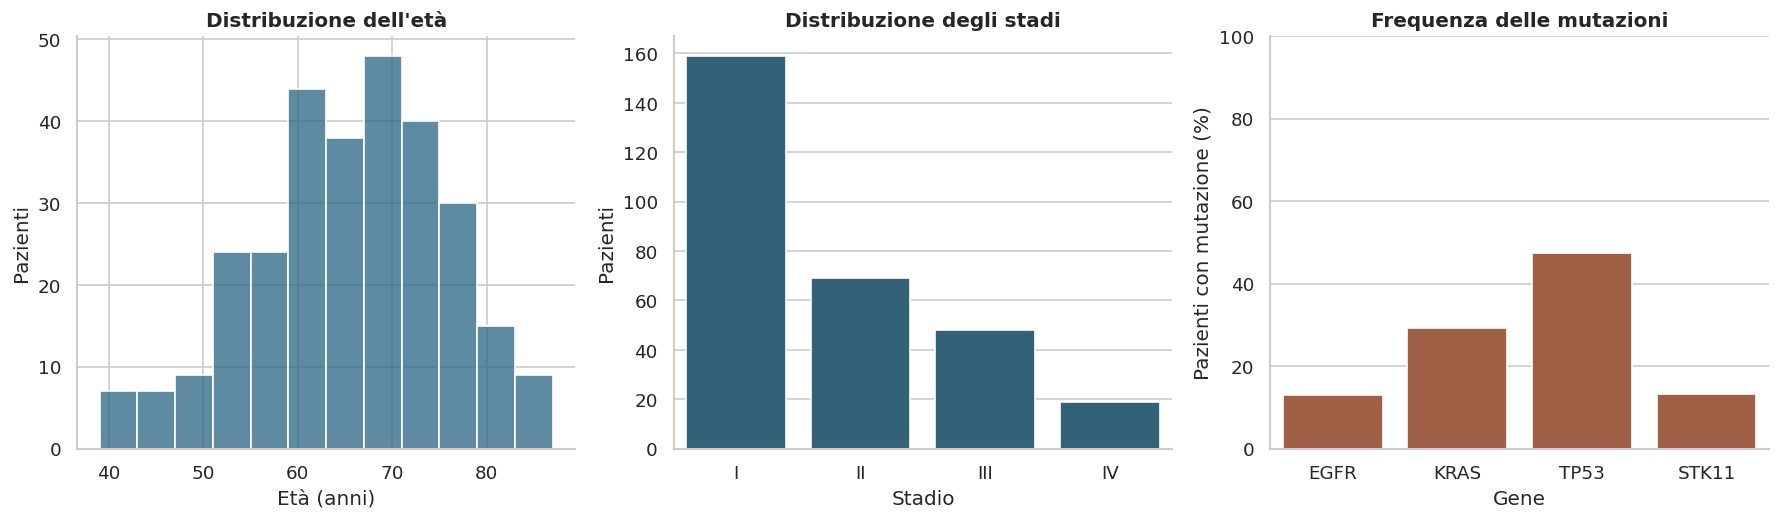

In [21]:
stage_summary = (
    df.groupby("stage", observed=False)["OS_STATUS"]
    .agg(pazienti="size", decessi="sum")
    .reindex(STAGES)
)
stage_summary["censurati"] = stage_summary["pazienti"] - stage_summary["decessi"]

mutation_summary = pd.DataFrame({
    "gene": GENES,
    "mutati_n": [int(df[g].sum()) for g in GENES],
    "mutati_percento": [100.0 * df[g].mean() for g in GENES],
    "decessi_tra_mutati": [
        int(df.loc[df[g] == 1, "OS_STATUS"].sum()) for g in GENES
    ],
})

print("Età, in anni:")
print(df["age"].describe().round(1).to_string())
print("\nStadio:")
print(stage_summary.to_string())
print("\nMutazioni:")
print(mutation_summary.round(1).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(data=df, x="age", bins=12, color="#286582", ax=axes[0])
axes[0].set(title="Distribuzione dell'età", xlabel="Età (anni)", ylabel="Pazienti")

sns.countplot(data=df, x="stage", order=STAGES, color="#286582", ax=axes[1])
axes[1].set(title="Distribuzione degli stadi", xlabel="Stadio", ylabel="Pazienti")

sns.barplot(
    data=mutation_summary, x="gene", y="mutati_percento",
    color="#AE5A36", ax=axes[2]
)
axes[2].set(
    title="Frequenza delle mutazioni", xlabel="Gene",
    ylabel="Pazienti con mutazione (%)", ylim=(0, 100)
)
fig.tight_layout()
plt.show()


### 5. Kaplan-Meier curves

Unadjusted survival by stage and by KRAS status, with 95% confidence intervals and numbers at risk.

In [22]:
def plot_km_groups(data, group_column, groups, labels, title):
    """Disegna curve KM e tabella dei pazienti a rischio con lifelines."""
    if len(groups) != len(labels):
        raise ValueError("groups e labels devono avere la stessa lunghezza.")

    fig, ax = plt.subplots(figsize=(9, 6))
    colors = sns.color_palette("colorblind", n_colors=len(groups))
    fitted_curves = []
    for group, label, color in zip(groups, labels, colors):
        subset = data.loc[data[group_column] == group]
        if subset.empty:
            raise ValueError(f"Gruppo senza pazienti: {group_column}={group}")

        kmf = KaplanMeierFitter(alpha=0.05)
        kmf.fit(
            durations=subset["OS_MONTHS"],
            event_observed=subset["OS_STATUS"],
            label=f"{label} (n={len(subset)})",
        )
        kmf.plot_survival_function(
            ax=ax, color=color, linewidth=2,
            ci_show=True, ci_alpha=0.12,
            show_censors=True,
            censor_styles={"marker": "|", "ms": 5},
        )
        fitted_curves.append(kmf)

    ax.set(
        title=title,
        xlabel="Tempo dall'origine documentata del follow-up (mesi)",
        ylabel="Probabilità di sopravvivenza",
        ylim=(0, 1.03),
    )
    ax.set_xlim(left=0)
    ax.legend(loc="best", frameon=True, fontsize=9)
    add_at_risk_counts(
        *fitted_curves, ax=ax, rows_to_show=["At risk"], ypos=-0.6
    )
    fig.tight_layout()
    plt.show()
    return fitted_curves


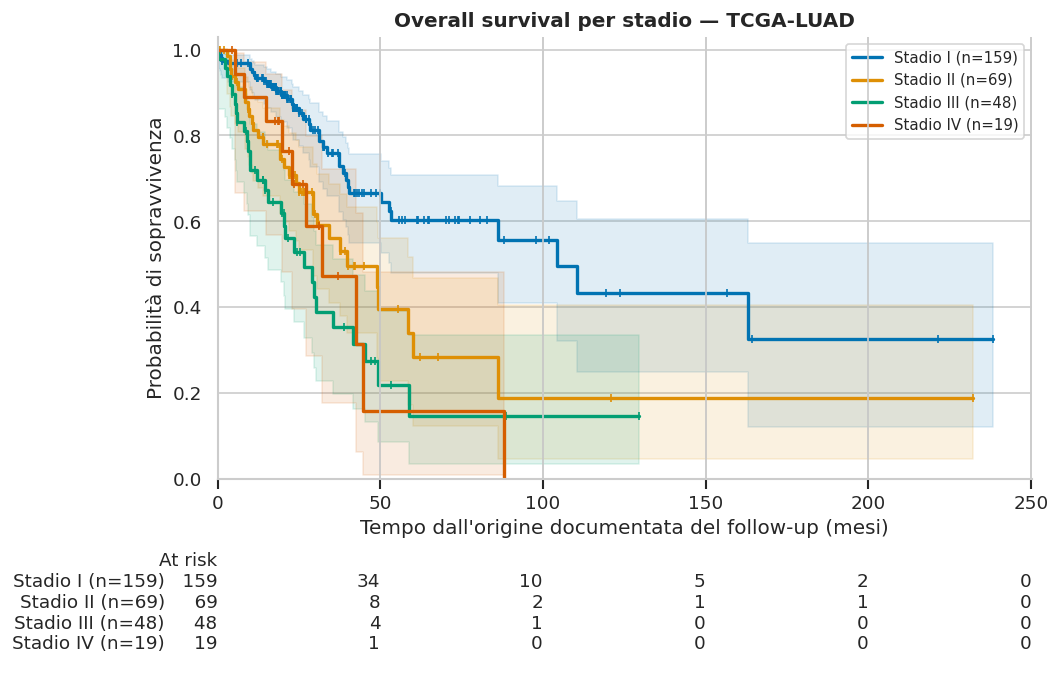

In [23]:
km_stage = plot_km_groups(
    df, "stage", STAGES,
    [f"Stadio {s}" for s in STAGES],
    "Overall survival per stadio — TCGA-LUAD",
)


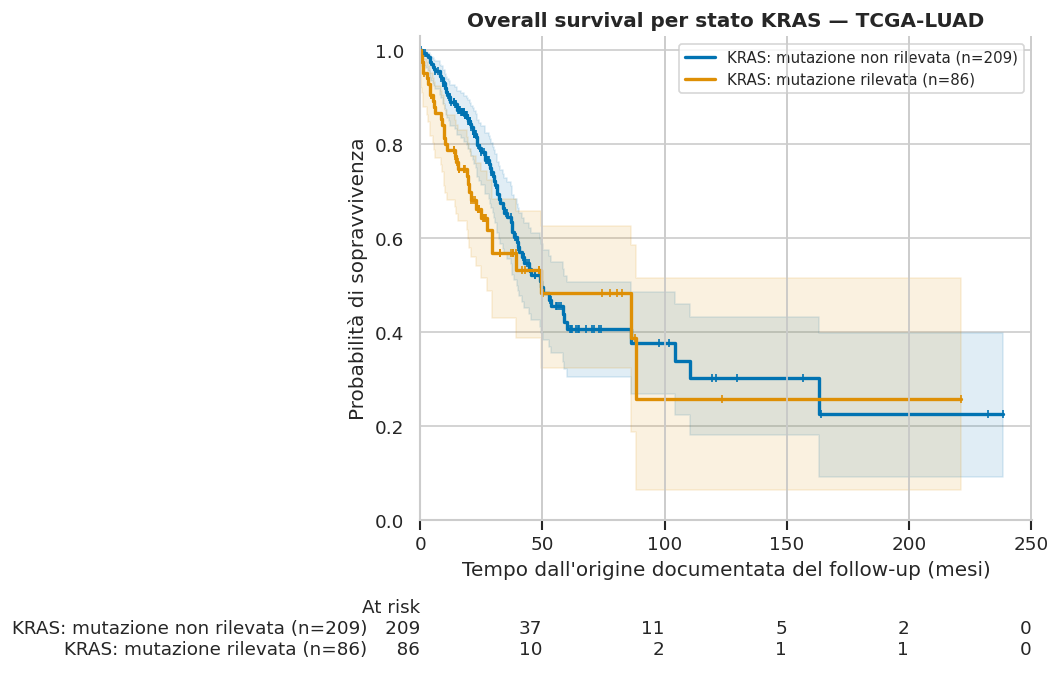

In [24]:
km_kras = plot_km_groups(
    df, "KRAS", [0, 1],
    ["KRAS: mutazione non rilevata", "KRAS: mutazione rilevata"],
    "Overall survival per stato KRAS — TCGA-LUAD",
)


### 6. Cox models

Both models are unpenalised, with the Efron method for ties.

In [25]:
def fit_cox(training_data, label):
    """Stima un Cox non penalizzato; non sostituisce modelli che non convergono."""
    model = CoxPHFitter(baseline_estimation_method="breslow", penalizer=0.0)
    try:
        model.fit(
            training_data,
            duration_col="OS_MONTHS",
            event_col="OS_STATUS",
            show_progress=False,
        )
    except ConvergenceError as error:
        raise RuntimeError(
            f"{label}: fit non convergente. Controllare collinearità, "
            "mutazioni rare, separazione e distribuzione degli eventi. "
            "Non interpretare il confronto finché il problema non è risolto."
        ) from error

    estimates = model.summary[["coef", "se(coef)"]]
    if (
        estimates.isna().any().any()
        or estimates.isin([float("inf"), -float("inf")]).any().any()
        or estimates["se(coef)"].le(0).any()
    ):
        raise RuntimeError(f"{label}: coefficienti o errori standard non validi.")
    return model

cph_m0 = fit_cox(train_m0, "M0 — clinico")
cph_m1 = fit_cox(train_m1, "M1 — clinico + genomica")
print("M0 — MODELLO CLINICO")
cph_m0.print_summary(decimals=4)
print("\nM1 — MODELLO CLINICO + GENOMICA")
cph_m1.print_summary(decimals=4)


M0 — MODELLO CLINICO


<lifelines.CoxPHFitter: fitted with 295 total observations, 186 right-censored observations>
             duration col = 'OS_MONTHS'
                event col = 'OS_STATUS'
      baseline estimation = breslow
   number of observations = 295
number of events observed = 109
   partial log-likelihood = -513.4492
         time fit was run = 2026-11-09 04:09:56 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
age_10    0.1379    1.1479    0.1013         -0.0606          0.3364              0.9412              1.3999
sex_M     0.1457    1.1569    0.1973         -0.2409          0.5323              0.7859              1.7029
stage_II  0.7995    2.2245    0.2419          0.3254          1.2737              1.3846              3.5739
stage_III 1.2496    3.4891    0.2471          0.7654          1.7339              2.1498              5.6626
stage_IV  1.0100    2.7455    0.3636          0.2973          1.7226              1.3463              5.5990

           cmp to      z      p  -log2(p)
covariate                                
age_10     0.0000 1.3618 0.1733    2.5290
sex_M      0.0000 0.7386 0.4601    1.1198
stage_II   0.0000 3.3052 0.0009   10.0411
stage_III  0.0000 5.0579 <5e-05   21.1696
stage_IV   0.0000 2.7777 0.0055    7.5131
---
Concordance = 0.6683
Partial AIC = 1036.8984
log-likelihood ratio test = 31.5006 on 5 df
-log2(p) of ll-ratio test = 17.0325


M1 — MODELLO CLINICO + GENOMICA


<lifelines.CoxPHFitter: fitted with 295 total observations, 186 right-censored observations>
             duration col = 'OS_MONTHS'
                event col = 'OS_STATUS'
      baseline estimation = breslow
   number of observations = 295
number of events observed = 109
   partial log-likelihood = -509.8366
         time fit was run = 2026-11-09 04:09:56 UTC

---
            coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                   
age_10    0.1993    1.2206    0.1051         -0.0066          0.4053              0.9934              1.4997
sex_M     0.1259    1.1342    0.2053         -0.2764          0.5283              0.7585              1.6960
stage_II  0.7337    2.0828    0.2442          0.2551          1.2123              1.2906              3.3612
stage_III 1.2240    3.4008    0.2552          0.7237          1.7243              2.0621              5.6085
stage_IV  0.9224    2.5153    0.3700          0.1972          1.6476              1.2180              5.1942
EGFR      0.2672    1.3063    0.2883         -0.2979          0.8322              0.7424              2.2984
KRAS      0.4427    1.5569    0.2280         -0.0043          0.8896              0.9957              2.4342
TP53      0.2665    1.3054    0.2031         -0.1315          0.6645              0.8768              1.9436
STK11     0.4434    1.5580    0.2877         -0.1204          1.0072              0.8865              2.7379

           cmp to      z      p  -log2(p)
covariate                                
age_10     0.0000 1.8974 0.0578    4.1134
sex_M      0.0000 0.6135 0.5395    0.8902
stage_II   0.0000 3.0049 0.0027    8.5560
stage_III  0.0000 4.7953 <5e-05   19.2318
stage_IV   0.0000 2.4930 0.0127    6.3027
EGFR       0.0000 0.9267 0.3541    1.4979
KRAS       0.0000 1.9412 0.0522    4.2590
TP53       0.0000 1.3124 0.1894    2.4006
STK11      0.0000 1.5413 0.1232    3.0205
---
Concordance = 0.6876
Partial AIC = 1037.6731
log-likelihood ratio test = 38.7258 on 9 df
-log2(p) of ll-ratio test = 16.2413

### 7. Apparent C-index

Harrell's C-index computed on the same data used to fit the models. It is optimistic; the correction is in section 10.

In [26]:
comparison = pd.DataFrame(
    {
        "pazienti": [len(train_m0), len(train_m1)],
        "decessi": [n_events, n_events],
        "coefficienti": [len(cph_m0.params_), len(cph_m1.params_)],
        "C_index_apparente": [
            float(cph_m0.concordance_index_),
            float(cph_m1.concordance_index_),
        ],
        "log_likelihood_parziale": [
            float(cph_m0.log_likelihood_),
            float(cph_m1.log_likelihood_),
        ],
    },
    index=["M0 — clinico", "M1 — clinico + genomica"],
)
delta_c = float(cph_m1.concordance_index_ - cph_m0.concordance_index_)
print(comparison.round(4).to_string())
print(f"\nDelta C apparente (M1 − M0): {delta_c:+.4f}")
print("Nessuna conclusione sulla generalizzazione deriva da questo valore da solo.")


                         pazienti  decessi  coefficienti  C_index_apparente  log_likelihood_parziale
M0 — clinico                  295      109             5             0.6683                -513.4492
M1 — clinico + genomica       295      109             9             0.6876                -509.8366

Delta C apparente (M1 − M0): +0.0193
Nessuna conclusione sulla generalizzazione deriva da questo valore da solo.


### 8. Likelihood-ratio test, M1 vs M0

The null hypothesis is that the four mutation coefficients are all zero given the clinical covariates:

$$LR = 2\{\ell(M1)-\ell(M0)\}, \qquad df = 9-5 = 4.$$

With 4 degrees of freedom the chi-square tail has a closed form, $P(\chi^2_4 \ge x)=e^{-x/2}(1+x/2)$, which is what the cell uses.

Note that `cph_m1.log_likelihood_ratio_test()` in lifelines compares M1 with the null model, not with M0, so the test is computed by hand here.

In [27]:
def chi_square_4_survival(statistic):
    """Coda chi-quadro con esattamente 4 df, in forma chiusa."""
    statistic = float(statistic)
    if not 0.0 <= statistic < float("inf"):
        raise ValueError("La statistica deve essere finita e non negativa.")
    half = statistic / 2.0
    euler_number = 2.718281828459045
    return (euler_number ** (-half)) * (1.0 + half)

# Il confronto deve essere proprio quello previsto dal protocollo.
if set(cph_m0.params_.index) != set(CLINICAL):
    raise RuntimeError("M0 non contiene i coefficienti clinici attesi.")
if set(cph_m1.params_.index) != set(INTEGRATED):
    raise RuntimeError("M1 non contiene i coefficienti attesi.")
df_added = len(cph_m1.params_) - len(cph_m0.params_)
if df_added != 4:
    raise RuntimeError("La formula del p-value implementata richiede esattamente 4 df.")

ll_m0 = float(cph_m0.log_likelihood_)
ll_m1 = float(cph_m1.log_likelihood_)
if not all(-float("inf") < x < float("inf") for x in [ll_m0, ll_m1]):
    raise RuntimeError("Log-verosimiglianze non finite.")

lr_raw = 2.0 * (ll_m1 - ll_m0)
if lr_raw < -1e-6:
    raise RuntimeError(
        "M1 annidato ha log-verosimiglianza inferiore a M0: "
        "controllare convergenza e identità dei dati."
    )
# Tolleranza solo per eventuale rumore numerico vicino allo zero.
lr_statistic = max(0.0, lr_raw)
lrt_p_value = chi_square_4_survival(lr_statistic)

lrt_m1_vs_m0 = StatisticalResult(
    p_value=lrt_p_value,
    test_statistic=lr_statistic,
    test_name="LRT annidato: M1 contro M0",
    degrees_of_freedom=df_added,
    null_distribution="chi-quadro; riferimento asintotico",
)
lrt_m1_vs_m0.print_summary(decimals=4)
print(f"\nLR = {lr_statistic:.4f}; df = {df_added}; p = {lrt_p_value:.6g}")
print(f"Delta C apparente = {delta_c:+.4f}; è una misura diversa dal LRT.")



LR = 7.2253; df = 4; p = 0.124453
Delta C apparente = +0.0193; è una misura diversa dal LRT.


### 9. Proportional-hazards diagnostics

Scaled Schoenfeld residuals with the rank and Kaplan-Meier time transformations, for both models.

DIAGNOSTICA M0

   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.





1. Variable 'sex_M' failed the non-proportional test: p-value is 0.0407.

   Advice: with so few unique values (only 2), you can include `strata=['sex_M', ...]` in the call
in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20ass



1. Variable 'KRAS' failed the non-proportional test: p-value is 0.0082.

   Advice: with so few unique values (only 2), you can include `strata=['KRAS', ...]` in the call in
`.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



[[<Axes: xlabel='rank-transformed time\n(p=0.5404)'>,
  <Axes: xlabel='km-transformed time\n(p=0.8161)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0587)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0722)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.6012)'>,
  <Axes: xlabel='km-transformed time\n(p=0.5797)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1096)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0814)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2260)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2851)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.2599)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1148)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0082)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0277)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1427)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1134)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.3085)'>,
  <Axes: xlabel='km-transformed time\n(p=0.4792)'>]]

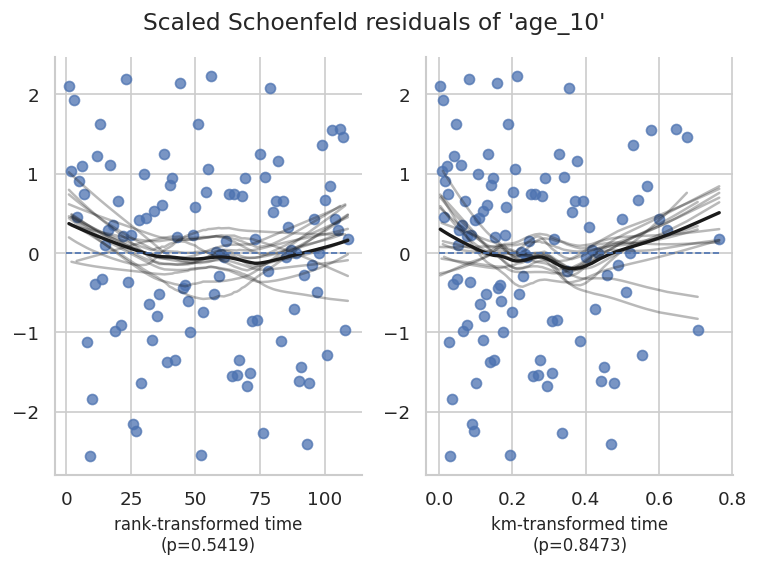

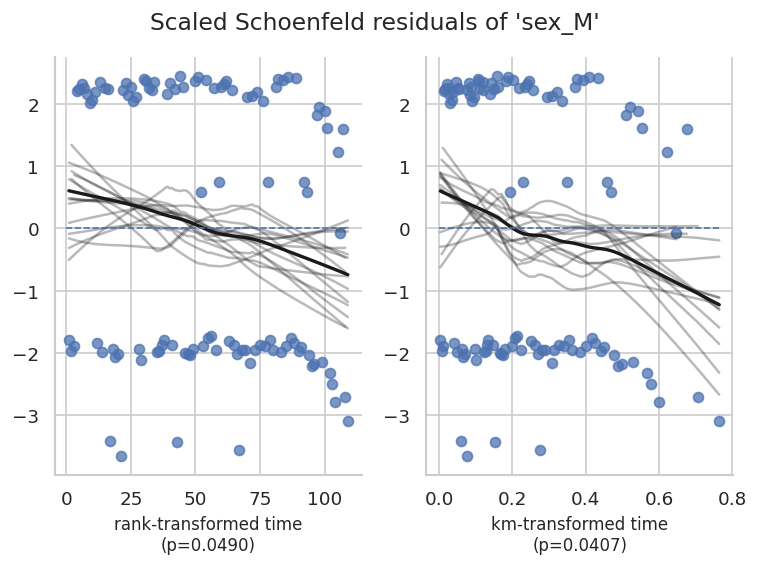

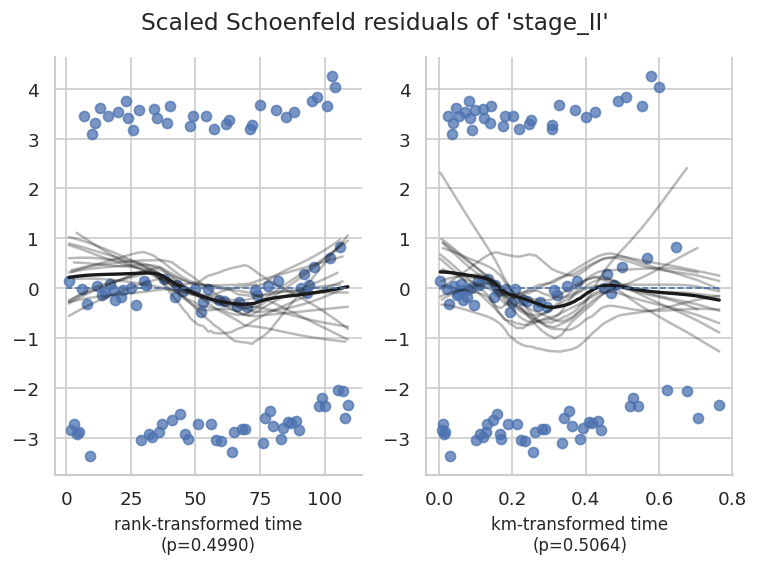

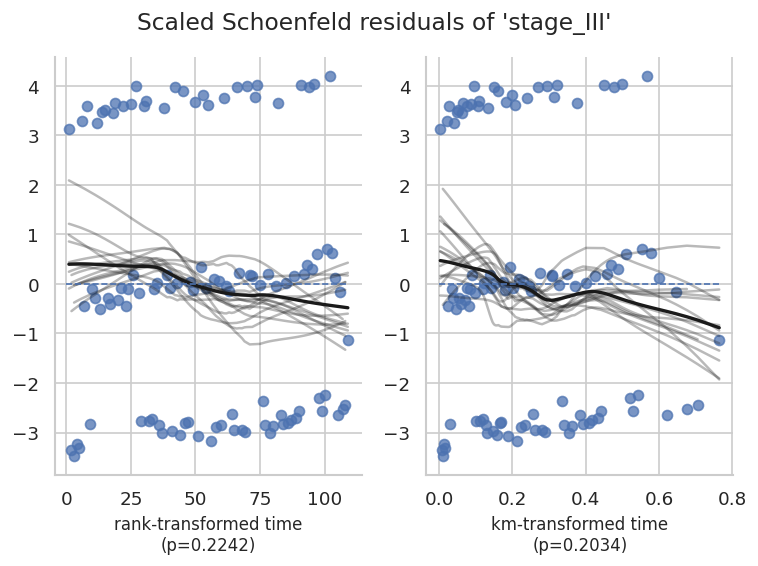

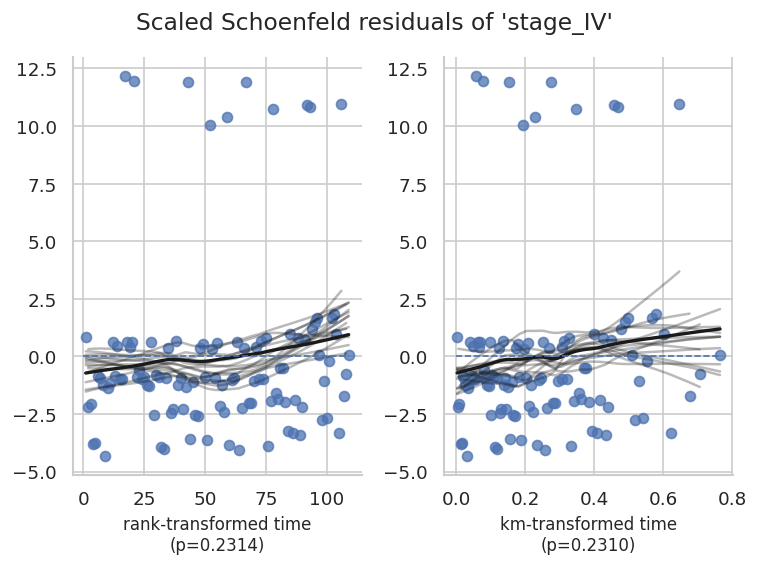

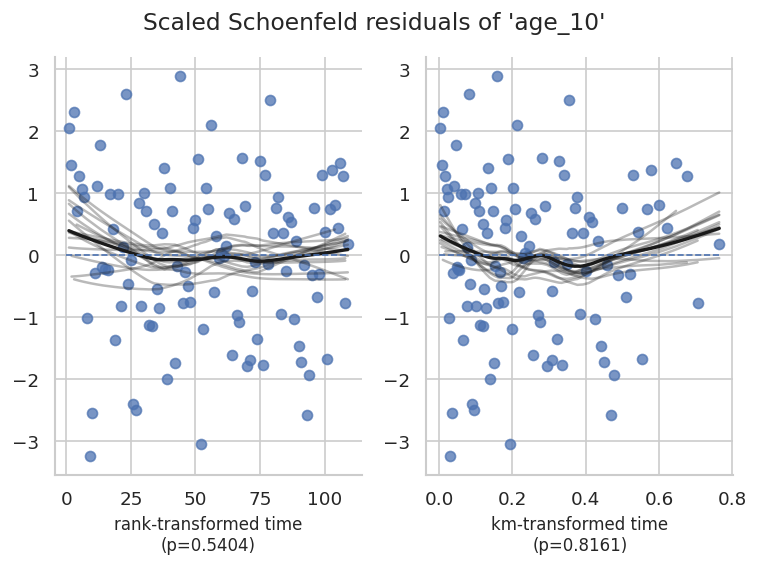

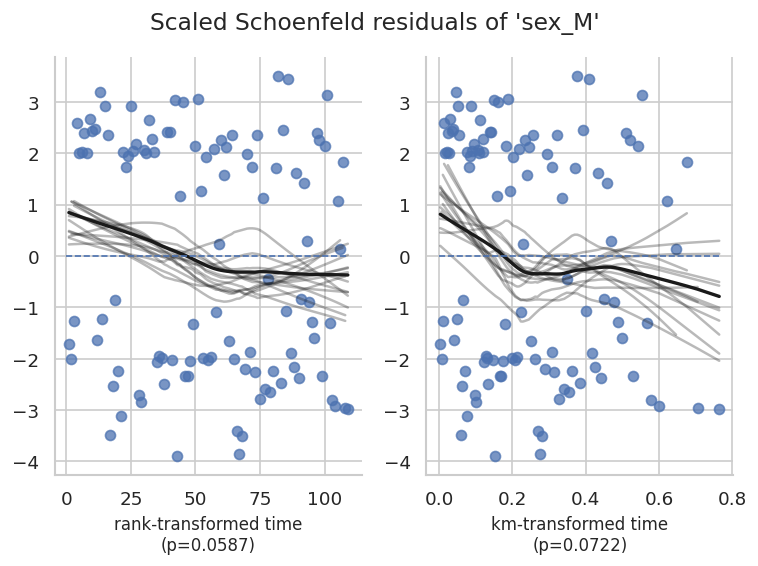

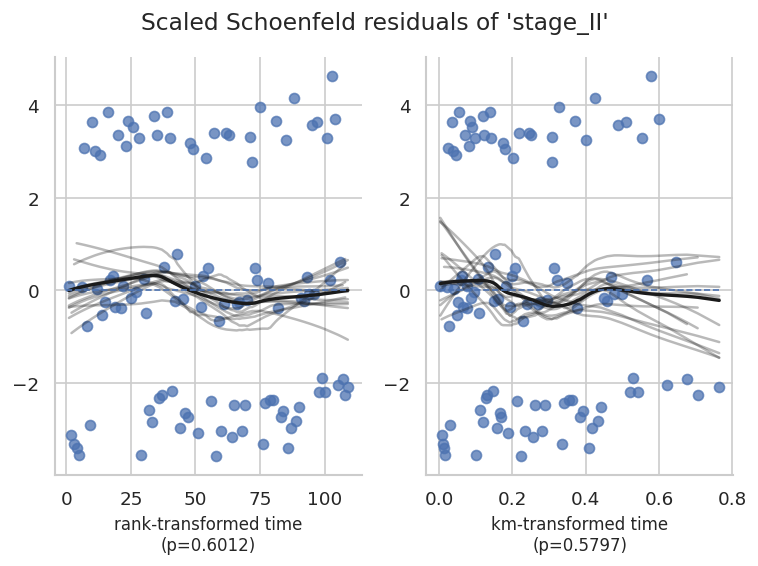

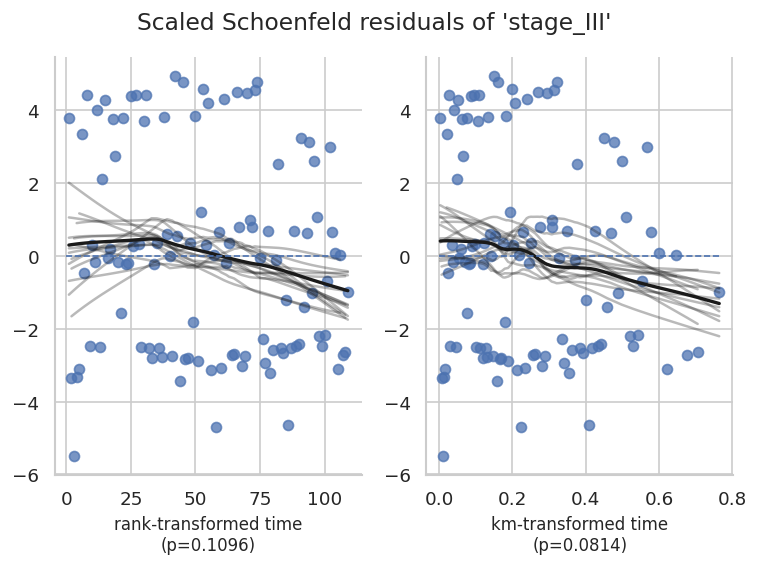

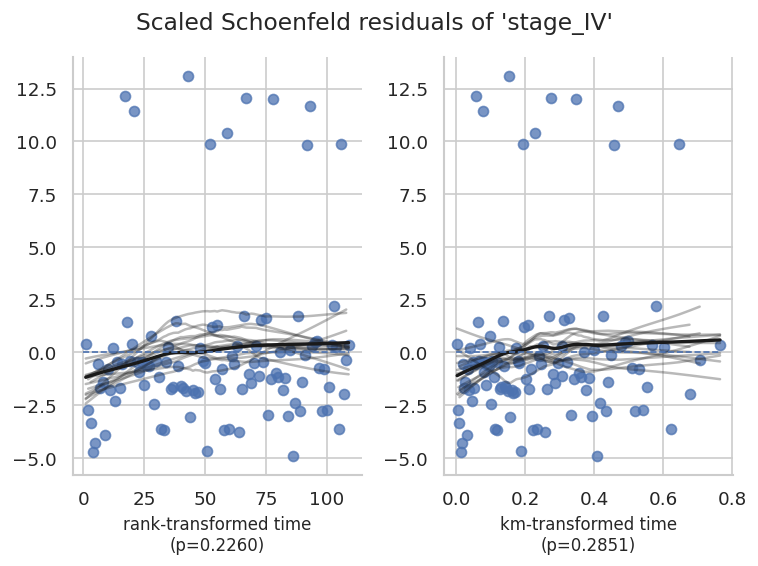

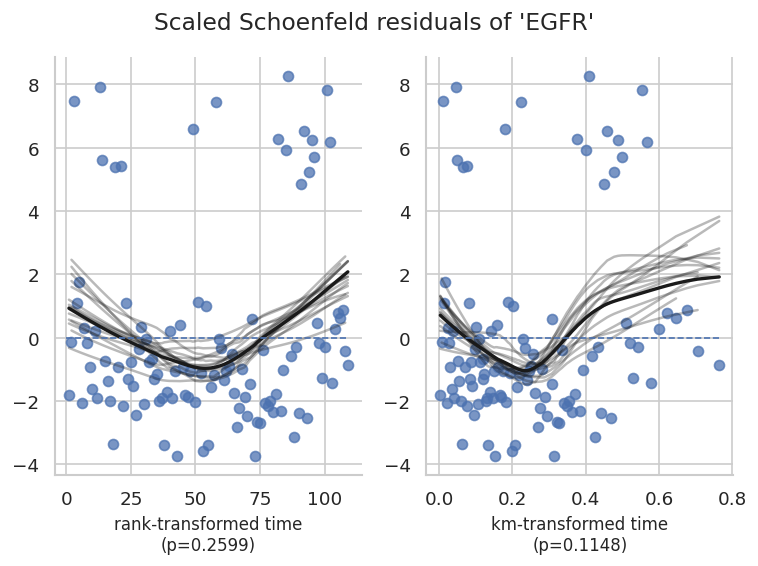

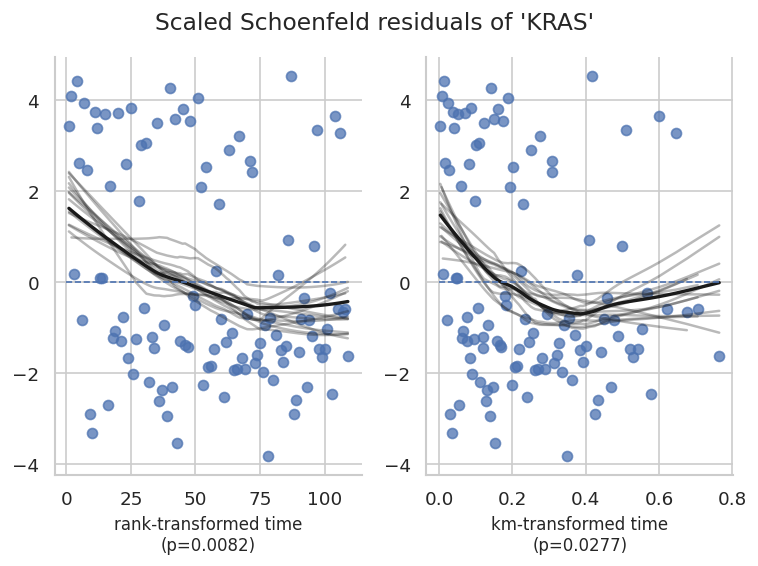

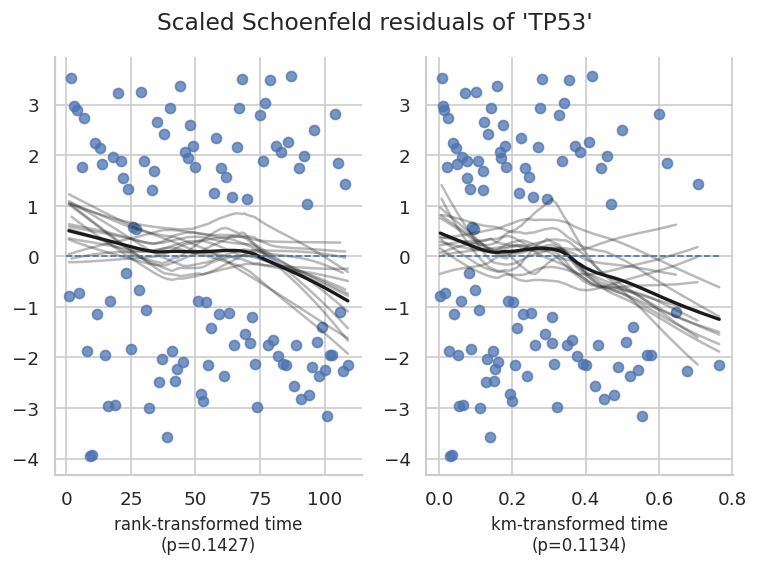

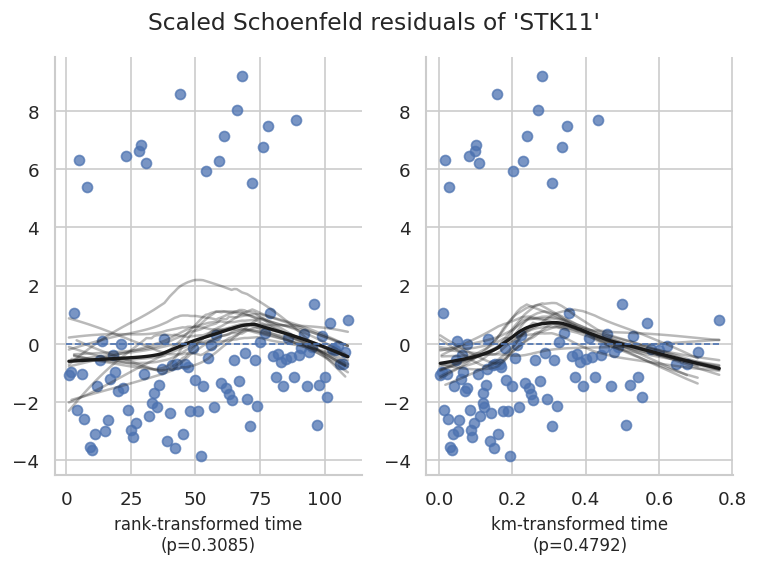

In [28]:
print("DIAGNOSTICA M0")
cph_m0.check_assumptions(
    train_m0, p_value_threshold=0.05, show_plots=True
)

print("DIAGNOSTICA M1")
cph_m1.check_assumptions(
    train_m1, p_value_threshold=0.05, show_plots=True
)

### 10. Bootstrap optimism correction

200 resamples of the 295 patients, drawn with replacement (seed 42). In each resample both models are refitted and scored twice: on the resample and on the original cohort. The difference is the optimism of that replicate. The mean optimism is subtracted from the apparent C-index, and the same is done for the difference between the two models.

Resamples that fail to converge would be excluded and counted; none did.

In [29]:
# ==========================================
# CELLA 2: BOOTSTRAP APPAIATO E AUDIT DELLA VALIDAZIONE INTERNA
# ==========================================
import warnings
import numpy as np
import pandas as pd
from lifelines.exceptions import ConvergenceWarning, ConvergenceError

# Configuration
N_BOOTSTRAPS = 200
SEED = 42
rng = np.random.RandomState(SEED)

# C-index apparenti baseline
c0_app = float(cph_m0.concordance_index_)
c1_app = float(cph_m1.concordance_index_)
delta_c_app = c1_app - c0_app

audit_records = []
valid_results = []

print(f"Avvio validazione bootstrap appaiata ({N_BOOTSTRAPS} tentativi, Seed={SEED})...\n")

for b in range(N_BOOTSTRAPS):
    # Ricampionamento appaiato con reimmissione
    boot_idx = rng.choice(model_data.index, size=len(model_data), replace=True)
    boot_data = model_data.loc[boot_idx].reset_index(drop=True)

    fit_failed = False
    iter_status = "VALID"
    iter_error = ""

    with warnings.catch_warnings(record=True) as recorded_warnings:
        warnings.simplefilter("always", ConvergenceWarning)

        try:
            # Fit dei modelli
            m0_boot = fit_cox(boot_data[TARGETS + CLINICAL], f"M0_boot_{b}")
            m1_boot = fit_cox(boot_data[TARGETS + INTEGRATED], f"M1_boot_{b}")
        except (ConvergenceError, RuntimeError) as e:
            # RuntimeError è accettato solo se originato da ConvergenceError
            is_conv_err = isinstance(e, ConvergenceError) or (
                isinstance(e, RuntimeError) and isinstance(e.__cause__, ConvergenceError)
            )
            if is_conv_err:
                fit_failed = True
                iter_status = "EXCLUDED_CONVERGENCE_ERROR"
                iter_error = f"{type(e).__name__}: {str(e)}"
            else:
                raise

        # Registrazione warning (anche in caso di eccezione di fit)
        iter_warnings = [
            str(w.message) for w in recorded_warnings if issubclass(w.category, ConvergenceWarning)
        ]

        if not fit_failed:
            if iter_warnings:
                iter_status = "EXCLUDED_CONVERGENCE_WARNING"
            else:
                # Valutazione C-index su campione bootstrap e dataset originale
                c0_boot = float(m0_boot.concordance_index_)
                c1_boot = float(m1_boot.concordance_index_)

                c0_orig = float(m0_boot.score(model_data[TARGETS + CLINICAL], scoring_method="concordance_index"))
                c1_orig = float(m1_boot.score(model_data[TARGETS + INTEGRATED], scoring_method="concordance_index"))

                # Controllo di validità dei C-index
                for val_name, val in [("c0_boot", c0_boot), ("c1_boot", c1_boot), ("c0_orig", c0_orig), ("c1_orig", c1_orig)]:
                    if not np.isfinite(val) or not (0.0 <= val <= 1.0):
                        raise ValueError(f"C-index non valido alla combinazione {b} ({val_name} = {val})")

                opt_m0 = c0_boot - c0_orig
                opt_m1 = c1_boot - c1_orig
                opt_delta = (c1_boot - c0_boot) - (c1_orig - c0_orig)

                valid_results.append({
                    'iteration': b,
                    'c0_boot': c0_boot,
                    'c0_orig': c0_orig,
                    'opt_m0': opt_m0,
                    'c1_boot': c1_boot,
                    'c1_orig': c1_orig,
                    'opt_m1': opt_m1,
                    'opt_delta': opt_delta
                })

        audit_records.append({
            'iteration': b,
            'status': iter_status,
            'num_warnings': len(iter_warnings),
            'warning_messages': "; ".join(iter_warnings),
            'error_message': iter_error
        })

# Creazione DataFrame di Audit e Risultati Validati
audit_df = pd.DataFrame(audit_records)
valid_df = pd.DataFrame(valid_results)

n_valid = len(valid_df)
n_err = (audit_df['status'] == "EXCLUDED_CONVERGENCE_ERROR").sum()
n_warn_excl = (audit_df['status'] == "EXCLUDED_CONVERGENCE_WARNING").sum()
total_warn_messages = audit_df['num_warnings'].sum()

print("--- CONTEGGI AUDIT ITERAZIONI ---")
print(f"Tentativi totali: {N_BOOTSTRAPS}")
print(f"Iterazioni valide (utilizzate per la stima): {n_valid}")
print(f"Iterazioni escluse per errore di convergenza: {n_err}")
print(f"Iterazioni escluse per warning di convergenza: {n_warn_excl}")
print(f"Messaggi di ConvergenceWarning totali intercettati: {total_warn_messages}")
print(f"Verifica quadratura conteggi: {n_valid + n_err + n_warn_excl == N_BOOTSTRAPS}")

if n_valid == 0:
    raise RuntimeError("Nessun ricampionamento bootstrap è risultato valido per il calcolo.")

# Calcolo delle metriche di ottimismo e correzione
mean_opt_m0 = float(valid_df['opt_m0'].mean())
mean_opt_m1 = float(valid_df['opt_m1'].mean())
mean_opt_delta = float(valid_df['opt_delta'].mean())

c0_corr = c0_app - mean_opt_m0
c1_corr = c1_app - mean_opt_m1
delta_c_corr = delta_c_app - mean_opt_delta

# Tabella Riassuntiva
summary_df = pd.DataFrame({
    'Modello': ['M0 (Clinico)', 'M1 (Clinico + Genomico)', 'Delta (M1 - M0)'],
    'C-index Apparente': [c0_app, c1_app, delta_c_app],
    'Ottimismo Medio': [mean_opt_m0, mean_opt_m1, mean_opt_delta],
    'C-index Corretto': [c0_corr, c1_corr, delta_c_corr]
})

print("\n--- TABELLA DI VALIDAZIONE INTERNA ---")
print(summary_df.to_string(index=False, float_format=lambda x: f"{x:+.4f}"))

print("\n----------------------------------------------------------------------")
print("NOTE SCIENTIFICHE SULLA VALIDAZIONE:")
print("1. Le stime sono calcolate sui soli ricampionamenti esenti da problemi di convergenza.")
print("2. Questa procedura costituisce una validazione interna e non sostituisce la verifica su una coorte indipendente.")
print("3. La dispersione dell'ottimismo non deve essere presentata come intervallo di confidenza del C-index corretto.")
print("----------------------------------------------------------------------")

Avvio validazione bootstrap appaiata (200 tentativi, Seed=42)...

--- CONTEGGI AUDIT ITERAZIONI ---
Tentativi totali: 200
Iterazioni valide (utilizzate per la stima): 200
Iterazioni escluse per errore di convergenza: 0
Iterazioni escluse per warning di convergenza: 0
Messaggi di ConvergenceWarning totali intercettati: 0
Verifica quadratura conteggi: True

--- TABELLA DI VALIDAZIONE INTERNA ---
                Modello  C-index Apparente  Ottimismo Medio  C-index Corretto
           M0 (Clinico)            +0.6683          +0.0147           +0.6536
M1 (Clinico + Genomico)            +0.6876          +0.0276           +0.6600
        Delta (M1 - M0)            +0.0193          +0.0129           +0.0064

----------------------------------------------------------------------
NOTE SCIENTIFICHE SULLA VALIDAZIONE:
1. Le stime sono calcolate sui soli ricampionamenti esenti da problemi di convergenza.
2. Questa procedura costituisce una validazione interna e non sostituisce la verifica su una co

### 11. Results

| | M0 | M1 | M1 − M0 |
|---|---:|---:|---:|
| Apparent C-index | 0.668 | 0.688 | +0.019 |
| Mean optimism | 0.015 | 0.028 | +0.013 |
| Corrected C-index | 0.654 | 0.660 | +0.006 |

- Likelihood-ratio test: 7.23 on 4 d.f., p = 0.12. Partial AIC: 1036.9 (M0) vs 1037.7 (M1).
- Stage is the dominant predictor in both models. The four mutation hazard ratios are between 1.31 and 1.56, all with confidence intervals that include 1.
- About two thirds of the apparent gain in C-index disappears after optimism correction.
- The Schoenfeld tests flag sex in M0 (p = 0.049 / 0.041) and KRAS in M1 (p = 0.008 / 0.028). The KRAS curves cross at about four years, so its hazard ratio is an average over follow-up.

Mutation status of these four genes adds little to stage for ranking patients by survival in this cohort.

### 12. Limitations

- The day-zero filter removes 40% of eligible patients (489 → 295).
- Internal validation only; no external cohort and no confidence interval for the corrected difference.
- The proportional-hazards assumption is doubtful for KRAS; no time-varying model was fitted.
- Treatment is not modelled.
- Follow-up is short (median 30.8 months) and few patients remain at risk after five years.

### References

- [cBioPortal, TCGA-LUAD PanCancer Atlas](https://www.cbioportal.org/study/summary?id=luad_tcga_pan_can_atlas_2018)
- Harrell FE, Lee KL, Mark DB. Stat Med 1996;15:361-387.
- Grambsch PM, Therneau TM. Biometrika 1994;81:515-526.
- [Iba K et al. BMC Med Res Methodol 2021;21:9](https://doi.org/10.1186/s12874-020-01201-w)
- [lifelines documentation](https://lifelines.readthedocs.io)

### 13. Export

Saves the environment, the input file hash and the 200 bootstrap records to `oncolung_run_audit.json`.

In [30]:
# Export the current run after the bootstrap. No models are refitted here.
import json
import sys
import hashlib
from pathlib import Path
from importlib.metadata import version

packages = ["numpy", "pandas", "scipy", "matplotlib", "seaborn", "lifelines", "formulaic"]
run_audit = {
    "environment": {
        "python": sys.version,
        "packages": {name: version(name) for name in packages},
    },
    "dataset": {
        "filename": Path(DATA_PATH).name,
        "sha256": hashlib.sha256(Path(DATA_PATH).read_bytes()).hexdigest(),
        "patients": int(len(model_data)),
        "events": int(model_data["OS_STATUS"].sum()),
    },
    "bootstrap": {
        "attempts": int(N_BOOTSTRAPS),
        "seed": int(SEED),
        "valid_iterations": int(len(valid_df)),
    },
    "summary": json.loads(summary_df.to_json(orient="records", double_precision=15)),
    "iteration_audit": json.loads(audit_df.to_json(orient="records")),
    "iteration_results": json.loads(valid_df.to_json(orient="records", double_precision=15)),
}
audit_path = Path("oncolung_run_audit.json")
audit_path.write_text(
    json.dumps(run_audit, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8"
)
print("Saved:", audit_path.resolve())

Saved: /content/oncolung_run_audit.json
